In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = DataLoader(trainset, batch_size=512, shuffle=True)

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = DataLoader(testset, batch_size=512, shuffle=False)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')
print(f"Training samples: {len(trainset)}")
print(f"Validation samples: {len(testset)}")

Training samples: 50000
Validation samples: 10000


In [4]:
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(3072, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.view(-1, 3072)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

mlp_model = MLP().to(device)
print("MLP Model initialized.")

MLP Model initialized.


In [5]:
import torchvision.models as models

def get_vgg_model(frozen=True):
    model = models.vgg11(weights='IMAGENET1K_V1')

    if frozen:
        for param in model.features.parameters():
            param.requires_grad = False

    model.classifier[6] = nn.Linear(4096, 10)
    return model.to(device)

vgg_frozen = get_vgg_model(frozen=True)
vgg_finetune = get_vgg_model(frozen=False)

print("VGG models (Frozen & Fine-tune) are ready!")

Downloading: "https://download.pytorch.org/models/vgg11-8a719046.pth" to /root/.cache/torch/hub/checkpoints/vgg11-8a719046.pth


100%|██████████| 507M/507M [00:05<00:00, 104MB/s] 


VGG models (Frozen & Fine-tune) are ready!


In [6]:
def train_model(model, train_loader, val_loader, epochs=10):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.001)
    train_losses = []
    val_accuracies = []
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        acc = 100 * correct / total
        train_losses.append(running_loss / len(train_loader))
        val_accuracies.append(acc)
        print(f"Epoch {epoch+1}/{epochs} - Loss: {train_losses[-1]:.4f} - Acc: {acc:.2f}%")

    return train_losses, val_accuracies

In [7]:
print("Starting training for Model 1: MLP...")
history_mlp = train_model(mlp_model, trainloader, testloader, epochs=10)

print("\nStarting training for Model 2: Frozen VGG-11...")
history_vgg_frozen = train_model(vgg_frozen, trainloader, testloader, epochs=10)

print("\nStarting training for Model 3: Fine-Tuned VGG-11...")
history_vgg_finetune = train_model(vgg_finetune, trainloader, testloader, epochs=10)

print("\nAll models trained successfully!")

Starting training for Model 1: MLP...
Epoch 1/10 - Loss: 1.6646 - Acc: 46.76%
Epoch 2/10 - Loss: 1.4232 - Acc: 49.91%
Epoch 3/10 - Loss: 1.3003 - Acc: 50.85%
Epoch 4/10 - Loss: 1.2138 - Acc: 52.63%
Epoch 5/10 - Loss: 1.1260 - Acc: 53.42%
Epoch 6/10 - Loss: 1.0449 - Acc: 52.38%
Epoch 7/10 - Loss: 0.9676 - Acc: 53.75%
Epoch 8/10 - Loss: 0.8821 - Acc: 54.14%
Epoch 9/10 - Loss: 0.8183 - Acc: 54.52%
Epoch 10/10 - Loss: 0.7451 - Acc: 53.80%

Starting training for Model 2: Frozen VGG-11...
Epoch 1/10 - Loss: 1.2535 - Acc: 66.93%
Epoch 2/10 - Loss: 1.0166 - Acc: 68.58%
Epoch 3/10 - Loss: 0.9657 - Acc: 69.02%
Epoch 4/10 - Loss: 0.9182 - Acc: 70.45%
Epoch 5/10 - Loss: 0.8876 - Acc: 70.55%
Epoch 6/10 - Loss: 0.8587 - Acc: 71.08%
Epoch 7/10 - Loss: 0.8221 - Acc: 71.18%
Epoch 8/10 - Loss: 0.7947 - Acc: 71.12%
Epoch 9/10 - Loss: 0.7728 - Acc: 71.41%
Epoch 10/10 - Loss: 0.7472 - Acc: 70.70%

Starting training for Model 3: Fine-Tuned VGG-11...
Epoch 1/10 - Loss: 2.2958 - Acc: 22.63%
Epoch 2/10 - Loss:

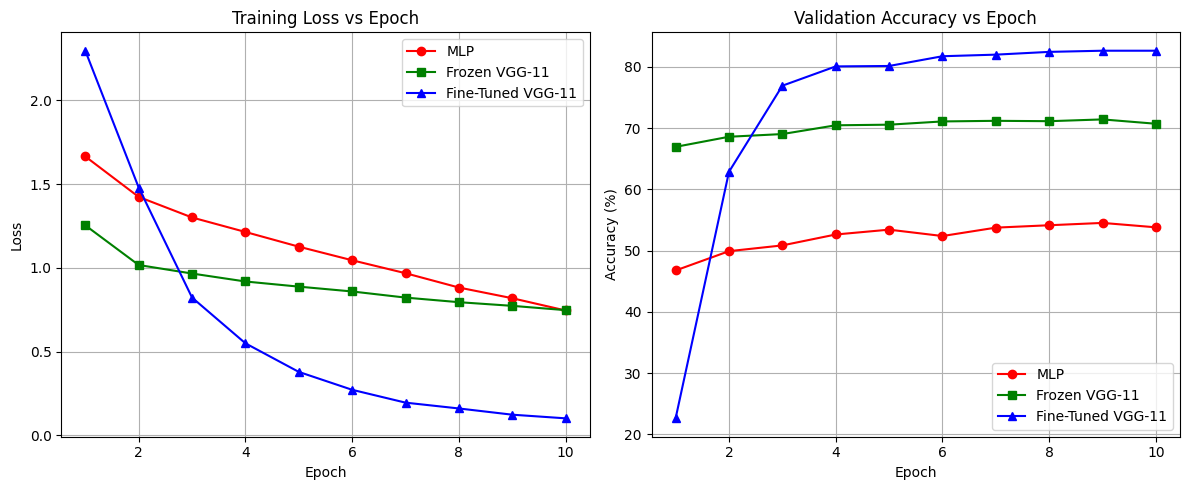

In [8]:
epochs = range(1, 11)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs, history_mlp[0], 'r-o', label='MLP')
plt.plot(epochs, history_vgg_frozen[0], 'g-s', label='Frozen VGG-11')
plt.plot(epochs, history_vgg_finetune[0], 'b-^', label='Fine-Tuned VGG-11')
plt.title('Training Loss vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, history_mlp[1], 'r-o', label='MLP')
plt.plot(epochs, history_vgg_frozen[1], 'g-s', label='Frozen VGG-11')
plt.plot(epochs, history_vgg_finetune[1], 'b-^', label='Fine-Tuned VGG-11')
plt.title('Validation Accuracy vs Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('results_comparison.png')
plt.show()

# بخش ۱۰: تحلیل نتایج یادگیری انتقالی (Transfer Learning)

### ۱. تحلیل همگرایی و پایداری (Convergence and Stability)

* **مدل Frozen VGG-11 (شروع سریع):**
    * **مشاهده:** این مدل پایدارترین روند همگرایی را داشت و در همان ای‌پوک اول به دقت حدود ۶۶٪ رسید.
    * **دلیل:** چون وزن‌های بخش استخراج ویژگی (Feature Extractor) منجمد بودند، بهینه‌سازی فقط روی لایه نهایی انجام شد. این مدل از قبل یاد گرفته بود که الگوهای بصری را تشخیص دهد، بنابراین بلافاصله نتایج خوبی ارائه داد.

* **مدل Fine-Tuned VGG-11 (پایان قهرمانانه):**
    * **مشاهده:** این مدل در ابتدا دقت پایینی داشت (حدود ۲۲٪)، اما از ای‌پوک سوم با سرعت بسیار زیاد از بقیه پیشی گرفت و به دقت نهایی بالای ۸۰٪ رسید.
    * **دلیل:** در ابتدا آپدیت شدن تمام لایه‌ها باعث تغییر ویژگی‌های از پیش‌آموزش‌دیده شد، اما بعد از چند مرحله، تمام پارامترهای شبکه خود را با جزئیات دیتاست CIFAR-10 تطبیق دادند که منجر به بهترین عملکرد شد.

* **مدل MLP Baseline:**
    * **مشاهده:** روند بهبود این مدل کندتر بود و در نهایت روی دقت ۵۴٪ متوقف (Plateau) شد.
    * **دلیل:** این مدل فاقد ساختار کانولوشنی است و باید تمام روابط بین پیکسل‌ها را از ابتدا و بدون هیچ دانش قبلی یاد بگیرد.

---

### ۲. شکاف تعمیم‌پذیری و سوگیری استقرایی (The Generalization Gap)

* **تناقض در Loss و Accuracy:**
    * در ای‌پوک ۱۰، میزان Loss آموزش برای **MLP** و **Frozen VGG** تقریباً مشابه و حدود **۰.۷۵** است.
    * با این حال، دقت آن‌ها روی داده‌های Validation تفاوت فاحشی دارد (**۵۴٪** در مقابل **۷۰٪**).

* **تفسیر نهایی (Inductive Bias):**
    * این موضوع نشان‌دهنده قدرت **سوگیری استقرایی** در شبکه‌های CNN است. هر دو مدل داده‌های آموزش را به یک اندازه یاد گرفته‌اند (Loss یکسان)، اما MLP صرفاً ترکیب پیکسل‌ها را حفظ کرده که به تصاویر جدید تعمیم نمی‌یابد.
    * ساختار کانولوشن در VGG ویژگی‌هایی مثل **Translation Invariance** (ثبات در جابه‌جایی) را به مدل تحمیل می‌کند که باعث می‌شود مدل حتی با لایه‌های منجمد، تعمیم‌دهی بسیار بالاتری نسبت به MLP داشته باشد.